In [11]:
%% Homework 4
% Due: 
% Ely Dawson

In [10]:
%% We’ve talked about least-squares fitting, and we’ve talked about the Fourier transform, 
%% so it’s time for us to test both strategies out using the same data set. Here we’ll
%% use the automated pressure data from the Scripps Pier. Use the function that you wrote previously.

%% For 2021, we will use data records 70521 through 88190, since these are nearly evenly
%% spaced in time. There are 4 gaps, that we will need to fill.

In [24]:
function pier = pierdata_2021(pointRange, filepath)
% this function pulls all relevant years of SIO pier data 
% inputs:
%  - pointRange: range you want to look for. 
%         enter as range [     ]
%      Ex: [100 500]
%  - filepath: specific filepath for finding the pier data
% originally created for SIOC-221a HW1
% updated for use in HW4 Oct 2026
%   - changed code to view range rather than seperate years. 
%   - data only available 2004 - 2023. Hardcoded for 2021 currently.
%   - made a more elegant solution for adding the missing data points
% Ely J Dawson, 28 October 2026

    if nargin < 2 || isempty(filepath)
        filepath = pwd;
    end

    filename = fullfile(filepath, 'scripps_pier-2021.nc');

    time = double(ncread(filename, 'time'));
    temp = double(ncread(filename, 'temperature'));
    pres = double(ncread(filename, 'pressure'));

    % Sort chronologically
    [time, idx] = sort(time(:));
    temp = temp(:);
    pres = pres(:);
    temp = temp(idx);
    pres = pres(idx);

    % Check and select the original measurement range
    validateattributes(pointRange, {'numeric'}, {'vector', 'numel', 2, 'integer', 'positive', '<=', numel(time)});

    assert(pointRange(1) <= pointRange(2), 'The first point must be less than or equal to the last point.');

    points = pointRange(1):pointRange(2);

    time = time(points);
    temp = temp(points);
    pres = pres(points);

    % Fill missing measurements on a 240-second grid
    pier.time = (time(1):240:time(end))';
    pier.t = interp1(time, temp, pier.time, 'linear');
    pier.p = interp1(time, pres, pier.time, 'linear');

    pier.dnum = datetime(pier.time, 'ConvertFrom', 'posixtime');
end

pier = pierdata_2021([70521 88190], '/Users/elydawson/SIO221a_Github_code_2026/data');

unique(diff(pier.time))

ans = 240

In [25]:
%% 1. Visual evaluation. 

% Plot the time series of pressure data from 2021, and examine
% the time increments between adjacent measurements. (You can do this in Matlab
% using the “diff” command or in python using “numpy.diff”, for example.) 

%% Are the data always uniformly spaced? 
% Before our correction, there were the 4 gaps. After our correction for those gaps, 
% we can see that the data is uniformly spaced at 240 seconds apart from each measurement

%% What is the increment between measurements?
% We can see from our second figure, that our increment is 240 seconds between measurements.

%% How long is the time record? 
% This time record spans a period from 16-Jul-2021 01:54:18 to 03-Sep-2021 04:06:18, or 49 days, 2 hours, and 12 minutes.

%% Are there other portions of the 2021 record that also have reliable uniform spacing?
% With my modification to the code, I can reliably do any portion of the data and always get 240 second spacing. 

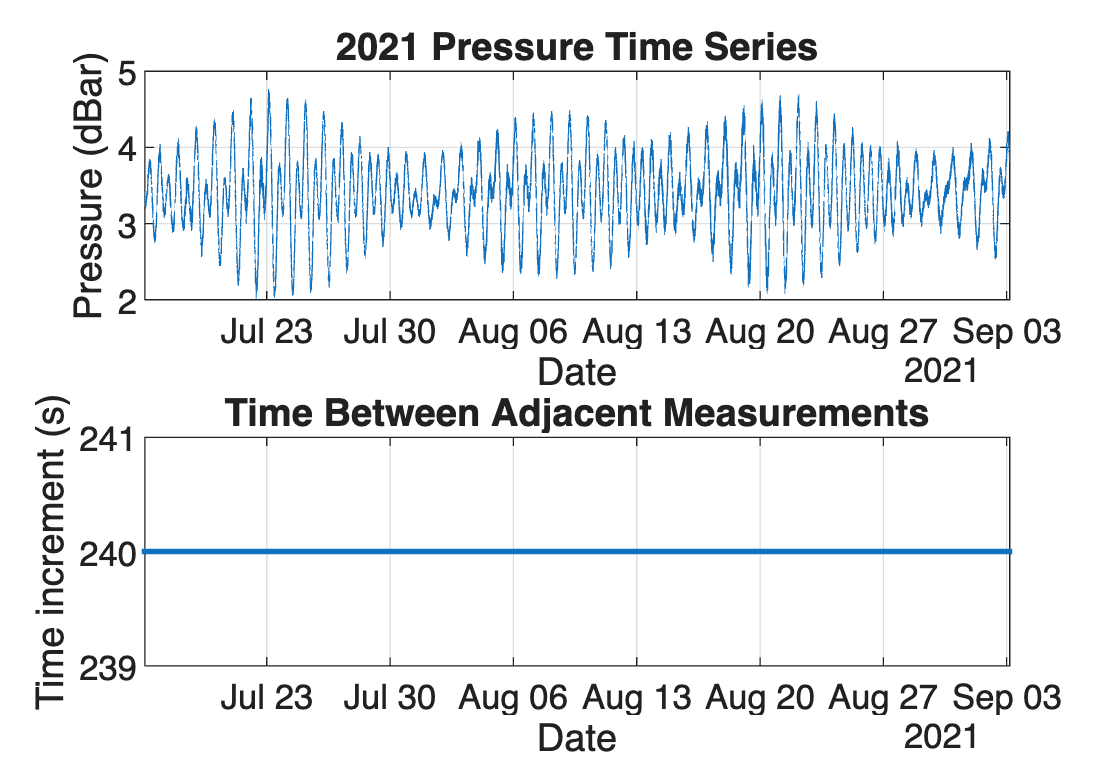

In [26]:
% Plot pressure time series
figure;
subplot(2,1,1)
plot(pier.dnum, pier.p)
xlabel('Date')
xlim([pier.dnum(1) pier.dnum(end)]);
ylabel('Pressure (dBar)')
title('2021 Pressure Time Series')
grid on

% Time increments between adjacent measurements
dt = diff(pier.time);

% Increment time series
subplot(2,1,2)
plot(pier.dnum(2:end), dt, '.')
xlabel('Date')
xlim([pier.dnum(1) pier.dnum(end)]);
ylabel('Time increment (s)')
title('Time Between Adjacent Measurements')
grid on

In [31]:
%% 2. Least-squares fit.

% Least-squares fit a mean and 3 major tidal constituents to your data. 
% Plot the raw and model solution.

%% What is the mean, and what are the total amplitudes of the tidal constituents?
%% (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.)
% The mean pressure is 3.4107 dBar from our fit. Tidal constituents are listed below:
% O1: 0.23332    
% K1: 0.36616    
% M2: 0.48337   

% I thought this turned out rather well. The tidal model follows our existing data rather closely.
% There are clear points where they are different such as around July 20-24th.

Fitted mean pressure: 3.4096 dBar
    Constituent    Amplitude_dBar
    ___________    ______________

       "O1"           0.23332    
       "K1"           0.36616    
       "M2"           0.48337    



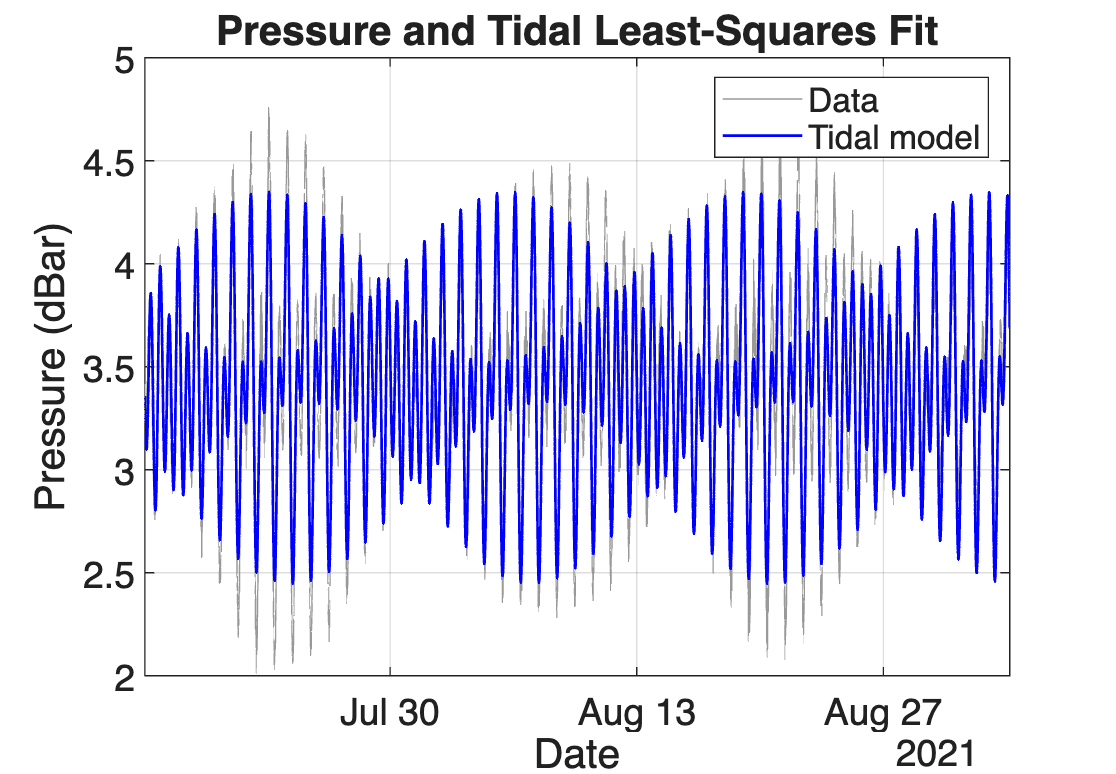

In [39]:
% Time in hours
t = (pier.time - pier.time(1))/3600;
p = pier.p;

% Tidal periods (hours): M2, S2, K1
names = ["O1"; "K1"; "M2"];
periods = [25.82, 23.93, 12.42];
omega = 2*pi./periods;

% Model: mean + sine and cosine for each constituent
A = [ones(size(t)), cos(t*omega), sin(t*omega)];

% Fit using finite pressure measurements
good = isfinite(p);
coef = A(good,:) \ p(good);
pfit = A*coef;

% Mean and total constituent amplitudes
meanPressure = coef(1);
amplitudes = sqrt(coef(2:4).^2 + coef(5:7).^2);

fprintf('Fitted mean pressure: %.4f dBar\n', meanPressure)
disp(table(names, amplitudes, 'VariableNames', {'Constituent', 'Amplitude_dBar'}))

% Plot data and fitted model
figure;
plot(pier.dnum, p, 'Color', [0.6 0.6 0.6])
hold on
plot(pier.dnum, pfit, 'b', 'LineWidth', 1)
xlabel('Date')
xlim([pier.dnum(1) pier.dnum(end)]);
ylabel('Pressure (dBar)')
title('Pressure and Tidal Least-Squares Fit')
legend('Data', 'Tidal model')
grid on

In [40]:
%% 3. Fourier transform. 

% Now Fourier transform your data. (Don’t worry about any
% of the details of computing a spectrum for this exercise—just Fourier transform.)

%% a. Plot the real and imaginary parts of the Fourier transform. Find the peaks.
%% What frequencies correspond to these peaks? Are they what you’d expect
%% based on the known tidal frequencies?
% We find the frequencies for O1, K1, M2 to be 0.93697, 0.99808, and 1.935 cycles per day.
% This does follow what our expected values would be. This is because with O1 and K1, we expect them
% to have a period of ~24 hours. This would lead to a cycle count of <1 per day, which is seen.
% As for M2, we expect a period of ~12 hours, thus a cycle count of ~2 is expected.
% This is exactly what we see as M2 is slightly larger than 12 thus our cycle count is <2. 

%% b. Now use the Fourier coefficients to identify the mean pressure and the ampli-
%% tudes of the major peaks. (Hint: to determine the amplitudes of the oscillatory
%% modes, you’ll need to multiply by a factor of 2 to account for both the positive
%% and negative frequencies.)
% Done. It all seems to make sense across the board. 

%% c. Do these spectral peaks align with the results from the least-squares fit? 
%% Is there anything you could do to further check your results?
% FFT amplitudes differ from the least-squares amplitudes because tidal frequencies can fall between FFT bins,
% thus spreading their energy across neighboring bins. This can be seen as there are slight differences between the
% LS_amp and the fft_amp shown below. The least-squares amplitude is ~0.02-0.04 greater than the fft amplitudes. \
% We can also see this is the differences between the means from the different fits. 
% Least-squares mean: 3.4096 dBar
% FFT mean:           3.4119 dBar

%% d. Now plot the spectral energy (based on the squared magnitude of the Fourier
%% coefficients) as a function of frequency. Is the spectrum red, white, or blue?
% Given the figure, we can see that the spectral energy is primarily red.
% We know this as we see that the values are higher at lower frequencies, and is not the same at all frequencies. 

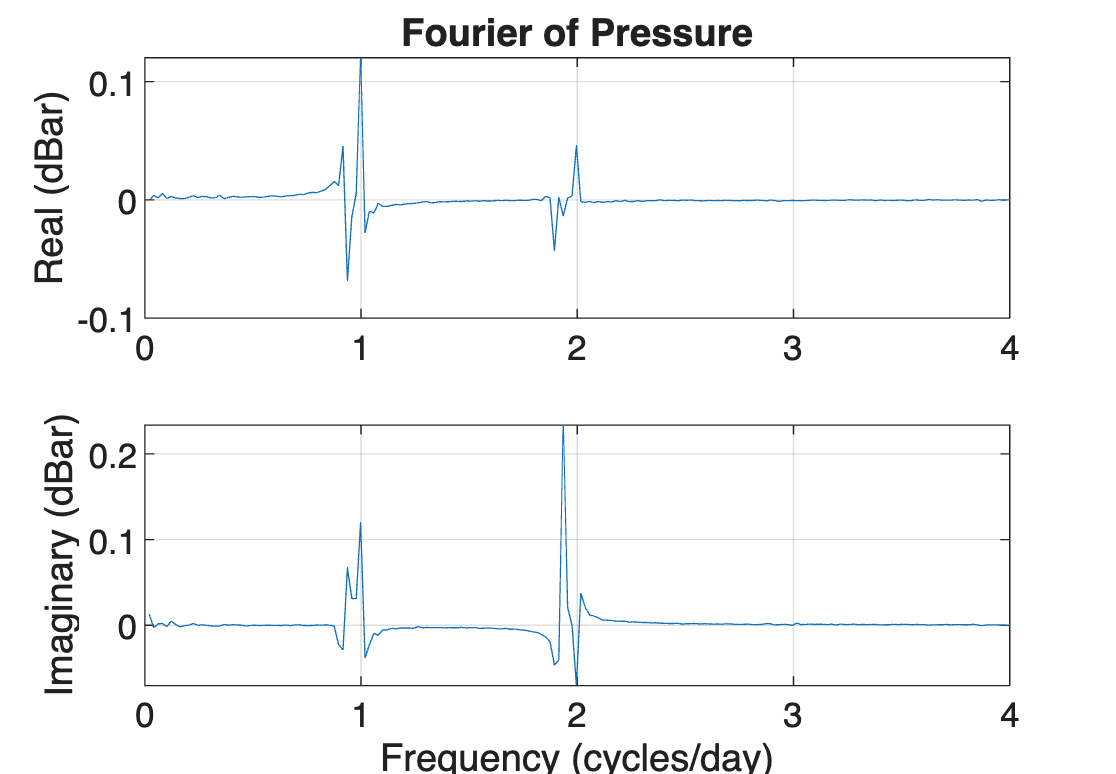

    CyclesPerDay    Period_hours    Amplitude_dBar
    ____________    ____________    ______________

        1.935          12.403          0.46786    
      0.99808          24.046          0.33905    
      0.93697          25.614          0.19079    

Mean pressure from FFT: 3.4119 dBar
    Constituent    ExpectedFrequency    FFT_binFrequency    LS_Amplitude    FFT_Amplitude
    ___________    _________________    ________________    ____________    _____________

       "O1"             0.92951             0.93697           0.23332          0.19079   
       "K1"              1.0029             0.99808           0.36616          0.33905   
       "M2"              1.9324               1.935           0.48337          0.46786   

Least-squares mean: 3.4096 dBar
FFT mean:           3.4119 dBar
Frequency spacing:  0.02037 cycles/day


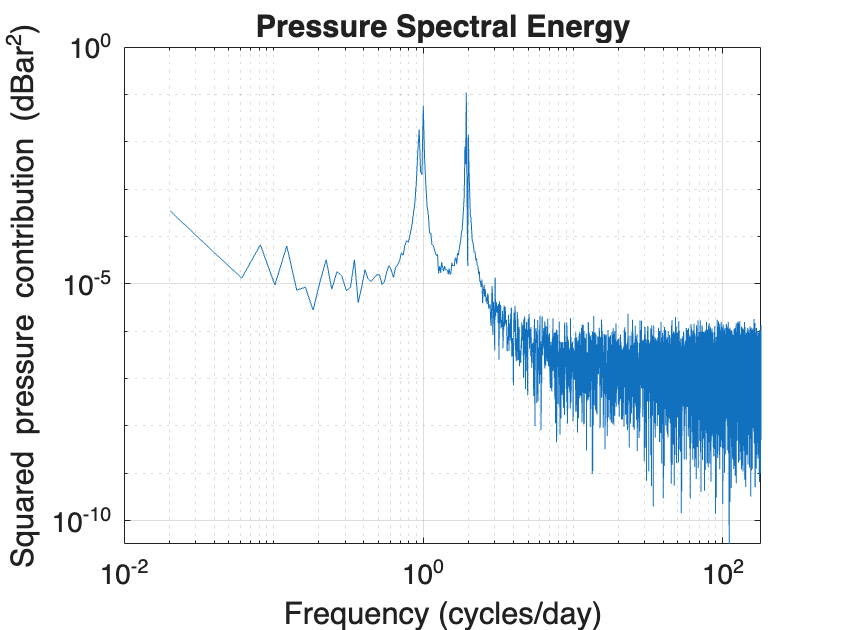

In [38]:
p = pier.p;
N = numel(p);
dt = median(diff(pier.time))/86400;

% Normalize so coefficients retain pressure units
F = fft(p)/N;

% Positive frequencies, excluding the mean and Nyquist frequency
idx = (2:floor((N+1)/2))';
f = (idx-1)/(N*dt);

%% a. Real and imaginary parts
figure;
subplot(2,1,1)
plot(f, real(F(idx)))
ylabel('Real (dBar)')
title('Fourier of Pressure')
xlim([0 4])
grid on

subplot(2,1,2)
plot(f, imag(F(idx)))
xlabel('Frequency (cycles/day)')
ylabel('Imaginary (dBar)')
xlim([0 4])
grid on

% Find local peaks using the magnitude of the complex coefficients
mag = abs(F(idx));
peakIdx = find(mag(2:end-1) > mag(1:end-2) & mag(2:end-1) >= mag(3:end)) + 1;

% Report the three largest peaks
[~, order] = sort(mag(peakIdx), 'descend');
peakIdx = peakIdx(order(1:min(3, numel(order))));

peakFrequency = f(peakIdx);
peakAmplitude = 2*mag(peakIdx);

disp(table(peakFrequency, 24./peakFrequency, peakAmplitude, 'VariableNames', ...
    {'CyclesPerDay', 'Period_hours', 'Amplitude_dBar'}))

%% b. Mean pressure and amplitudes

fftMean = real(F(1));
fprintf('Mean pressure from FFT: %.4f dBar\n', fftMean)

% Fourier bins nearest the three fitted tidal frequencies
tidalFrequency = 24./periods(:);
bin = round(tidalFrequency*N*dt) + 1;

fftFrequency = (bin-1)/(N*dt);
fftAmplitude = 2*abs(F(bin));

%% c. Compare with the least-squares fit

disp(table(names, tidalFrequency, fftFrequency, amplitudes, fftAmplitude, ...
    'VariableNames', {'Constituent', 'ExpectedFrequency', ...
    'FFT_binFrequency', 'LS_Amplitude', 'FFT_Amplitude'}))

fprintf('Least-squares mean: %.4f dBar\n', meanPressure)
fprintf('FFT mean:           %.4f dBar\n', fftMean)
fprintf('Frequency spacing:  %.5f cycles/day\n', 1/(N*dt))

%% d. Spectral energy

% Combine energy from positive and negative frequencies
energy = 2*abs(F(idx)).^2;

figure;
loglog(f, energy)
xlabel('Frequency (cycles/day)')
ylabel('Squared pressure contribution (dBar^2)')
title('Pressure Spectral Energy')
grid on